# Lunar Landing-Site Suitability Pipeline

**Goal:** score terrain for crewed-landing suitability by combining three real, independently-motivated signals:

1. **Crater hazard** -- detected with classical computer vision on real elevation data, cross-checked against a published crater catalog.
2. **Slope / roughness hazard** -- computed directly from real elevation data.
3. **Illumination benefit** -- modeled two different ways depending on latitude (see below).

Two case-study regions are analyzed:

- **Region A -- Tycho crater (43.3S, 11.2W).** A real global lunar DEM, real crater catalog, and every derived layer computed directly from genuine per-pixel elevation.
- **Region B -- Malapert Massif (~86S).** One of NASA's 13 publicly announced candidate landing regions for Artemis III. Analyzed directly from NASA GSFC's real 5 m/pixel PGDA LOLA digital elevation model for the site, combined with the same real Head et al. crater catalog used at Tycho.

See `README.md` in the project root for full data provenance, methodology, and known limitations.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import numpy as np

from landing_site import data, terrain, craters, illumination, scoring, real_polar_dem, regions, viz
from landing_site.data import MOON_RADIUS_M

DATA_DIR = "../data"
%matplotlib inline

## Region A: Tycho crater -- real DEM, real crater catalog

### Data sources
- **Elevation**: a global 1180 m/pixel equirectangular DEM (+/-60 deg latitude), derived from the merged LRO LOLA + Kaguya Terrain Camera 59 m/pixel topography (the basis of SLDEM2015). This exact file is distributed as test data with [DeepMoon](https://github.com/silburt/DeepMoon) (Silburt et al. 2019, *Icarus* 317).
- **Crater catalog**: Head et al. (2010), *Science* 329 -- every lunar crater >= 20 km diameter, globally.

We crop a 10x10 degree window (~250 km) centered on Tycho, a young, well-studied, heavily-cratered highland crater.

In [2]:
dem = data.GlobalDem(f"{DATA_DIR}/LunarLROLrocKaguya_1180mperpix_downsamp.png")
catalog = data.load_head_catalog(f"{DATA_DIR}/HeadCraters.csv")

region_a = regions.REGION_TYCHO
print(region_a.description)

crop_a = dem.crop(region_a.lat_center, region_a.lon_center, region_a.half_width_deg)
catalog_window_a = data.craters_in_window(catalog, crop_a.lat_bounds, crop_a.lon_bounds)

print(f"\nCrop: {crop_a.shape[0]}x{crop_a.shape[1]} px, real extent {crop_a.extent_km()[0]:.0f} x {crop_a.extent_km()[1]:.0f} km")
print(f"Catalog craters (>=20km) in this window: {len(catalog_window_a)}")

Tycho crater (43.3S, 11.2W), a young ~85 km rayed highland crater with a prominent central peak, surrounded by numerous smaller superimposed craters. Chosen as the primary demo region because it lies well inside the real DEM's +/-60 deg coverage and gives the crater detector a rich, real, and independently-cataloged scene to work with.

Crop: 256x256 px, real extent 221 x 303 km
Catalog craters (>=20km) in this window: 20


### Step 1 -- classical CV crater detection

Craters are topographic bowls, so we detect them as blobs in scale-space on the *negated* elevation surface (crater floors become local maxima) using Laplacian-of-Gaussian blob detection (`skimage.feature.blob_log`). This is a transparent, explainable baseline -- see the README for the optional YOLOv8 fine-tuning upgrade path over this.

We validate detections against the real Head et al. catalog. Since that catalog only contains craters >= 20 km, we report **recall** (how many real catalogued craters we found) as the meaningful accuracy number -- **precision looks artificially low only because most of our detections are genuine smaller craters the coarse catalog simply doesn't include.**

In [3]:
dets_a = craters.detect_craters(crop_a)
val_a = craters.validate_against_catalog(dets_a, catalog_window_a)

print(f"CV detections: {len(dets_a.lat)}")
print(f"Catalog craters (>=20km) matched: {val_a.n_matched}/{val_a.n_catalog_in_window}  (recall = {val_a.recall_ge20km:.0%})")
print(f"Remaining detections (smaller, or unmatched): {val_a.n_uncatalogued_candidates}")

CV detections: 108
Catalog craters (>=20km) matched: 18/20  (recall = 90%)
Remaining detections (smaller, or unmatched): 90


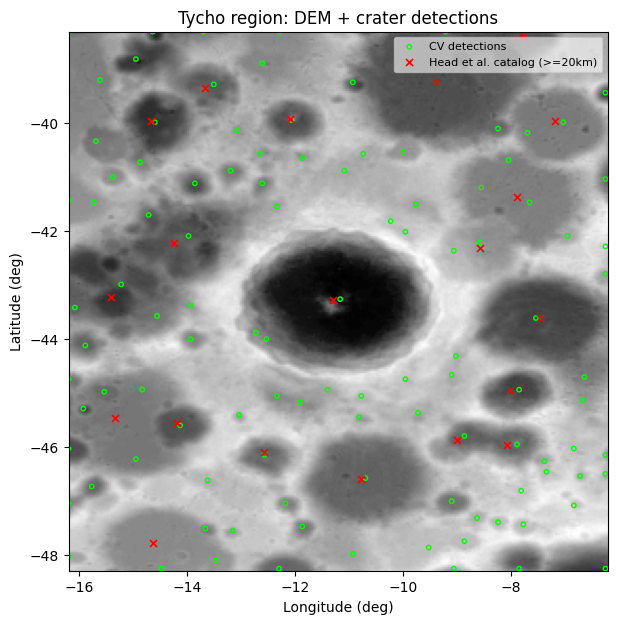

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
viz.plot_dem_with_craters(crop_a, dets_a, catalog_window_a, "Tycho region: DEM + crater detections", ax=ax)
plt.show()

### Step 2 -- slope and roughness from real elevation

Both are computed with plain numpy from the DEM crop: slope from the elevation gradient (scaled by real meters/pixel in each direction), roughness from a local elevation standard deviation (a standard terrain-ruggedness proxy).

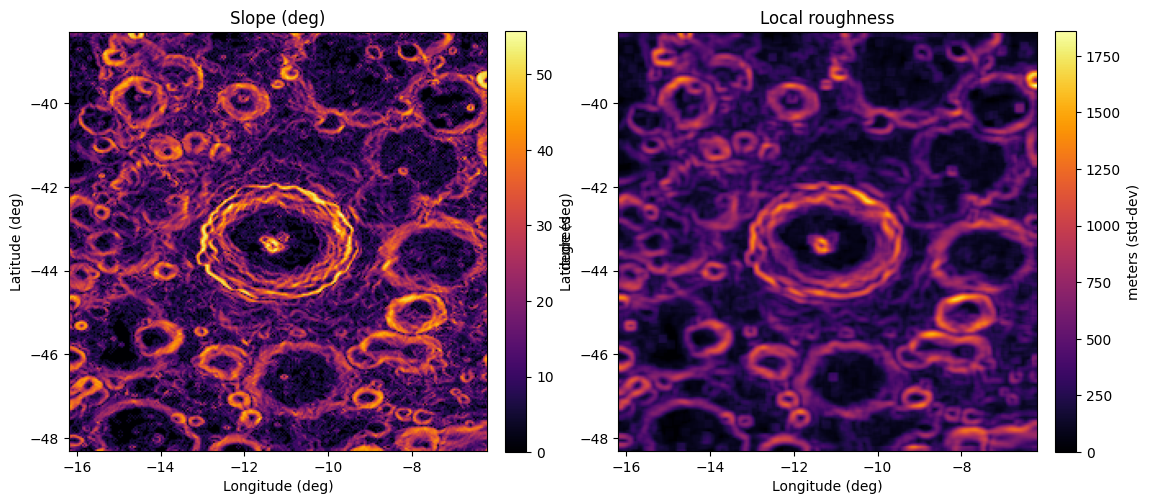

In [5]:
tm_a = terrain.compute_terrain_metrics(crop_a)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
viz.plot_layer(tm_a.slope_deg, crop_a, "Slope (deg)", "inferno", "degrees", ax=axes[0])
viz.plot_layer(tm_a.roughness_m, crop_a, "Local roughness", "inferno", "meters (std-dev)", ax=axes[1])
plt.show()

### Step 3 -- illumination

At Tycho's latitude (43S) the Moon's tiny 1.54 deg axial tilt keeps the sun's elevation moderate (never grazing) -- so the dominant effect is the standard Lambertian cosine-incidence law: slopes facing the sun get more light per unit area than slopes facing away. This is computed exactly from the DEM's slope and aspect for one representative sun position.

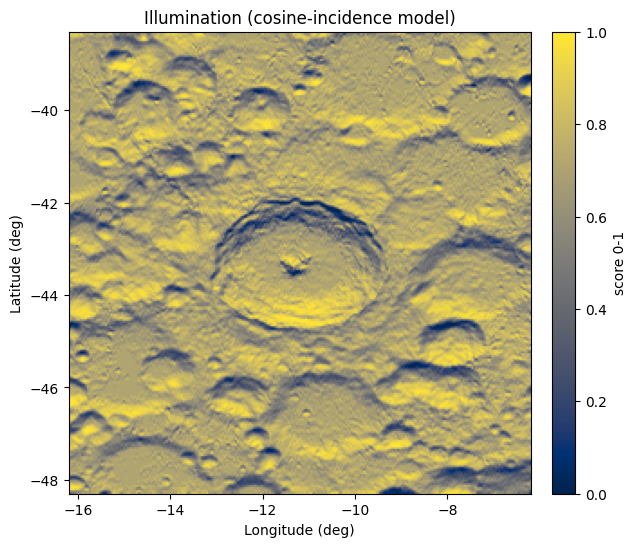

In [6]:
illum_a = illumination.mid_latitude_incidence(crop_a)

fig, ax = plt.subplots(figsize=(7, 6))
viz.plot_layer(illum_a, crop_a, "Illumination (cosine-incidence model)", "cividis", "score 0-1", ax=ax, vmin=0, vmax=1)
plt.show()

### Step 4 -- composite suitability score

Best-scoring site: lat=-38.300, lon=-13.192, score=91.2/100


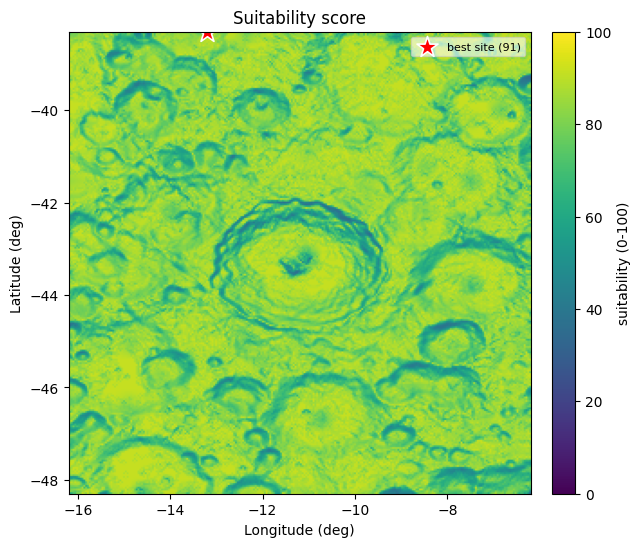

In [7]:
density_a = craters.crater_density_map(crop_a, dets_a, grid_cells=32)
suitability_a = scoring.compute_suitability(density_a, tm_a.slope_deg, illum_a)
best_a = scoring.best_site(suitability_a, crop_a)

print(f"Best-scoring site: lat={best_a['lat']:.3f}, lon={best_a['lon']:.3f}, score={best_a['score']:.1f}/100")

fig, ax = plt.subplots(figsize=(7, 6))
viz.plot_suitability(suitability_a, crop_a, best=best_a, ax=ax)
plt.show()

---
## Region B: Malapert Massif -- real DEM, real craters

### Data source

This region is analyzed directly from NASA GSFC's PGDA (Planetary Geodesy and Geophysics
group) real 5 m/pixel south-pole LOLA elevation tile for the Malapert Massif site
(`Site23_final_adj_5mpp_surf.tif`), a GeoTIFF in south polar stereographic projection. It is
loaded with `real_polar_dem.py`, which reads the tile's own embedded map projection metadata
(via `rasterio`/`pyproj`) rather than assuming any hand-typed coordinates -- important, because
this site tile is a small, fixed footprint (~21x21 km), not an open-ended mosaic that can be
cropped anywhere.

A note on where the analysis coordinates come from: an early version of this project used a
hand-typed center coordinate for "Malapert" that turned out to be *Malapert crater's*
catalogued center (a related but distinct feature, about 33 km from the massif's true summit
ridge). To avoid that kind of mixup, this notebook instead reads the real tile's own true
footprint directly from its metadata via `real_polar_dem.raster_footprint_latlon()`, so the
crop requested is guaranteed to match what the file actually contains.

*Methodology note:* an earlier, now-superseded prototype (`synthetic.py`) built a labeled
synthetic terrain for this site before the real PGDA tile had been downloaded and integrated.
It contributes to none of the results below and is kept in the codebase only as a record of
early pipeline development -- see `CODE_WALKTHROUGH.md` Section 7 for the full story.

In [8]:
catalog = data.load_head_catalog(f"{DATA_DIR}/HeadCraters.csv")
REAL_DEM_PATH = f"{DATA_DIR}/Site23_final_adj_5mpp_surf.tif"

# Read the real tile's own true footprint from its embedded metadata, rather
# than trusting a hand-typed coordinate (see the note above).
footprint = real_polar_dem.raster_footprint_latlon(REAL_DEM_PATH)
print(f"Real tile footprint: {footprint['width_km']:.1f} x {footprint['height_km']:.1f} km, "
      f"centered at lat={footprint['lat_center']:.3f}, lon={footprint['lon_center']:.3f}")

r = regions.REGION_MALAPERT
km_per_deg_lat = np.pi * MOON_RADIUS_M / 1000.0 / 180.0  # ~30.3 km/deg on the Moon
lat_offset_km = (footprint["lat_center"] - r.lat_center) * km_per_deg_lat
print(f"(regions.py's early prototype center is lat={r.lat_center:.3f}, lon={r.lon_center:.3f} "
      f"-- about {abs(lat_offset_km):.0f} km away in latitude alone; see the note above.)")

crop_b = real_polar_dem.load_real_polar_dem(
    REAL_DEM_PATH,
    lat_center=footprint["lat_center"],
    lon_center=footprint["lon_center"],
    half_width_km=footprint["safe_half_width_km"],
    target_pixels=800,
)
print(f"\nLoaded real DEM crop: {crop_b.shape[0]}x{crop_b.shape[1]} px, "
      f"{crop_b.extent_km()[0]:.1f} x {crop_b.extent_km()[1]:.1f} km, "
      f"effective resolution {crop_b.mpp_ew:.1f} m/pixel")

catalog_window_b = data.craters_in_window(catalog, crop_b.lat_bounds, crop_b.lon_bounds)
print(f"Real catalog craters (>=20km) inside this window: {len(catalog_window_b)}")

Real tile footprint: 21.0 x 21.0 km, centered at lat=-85.995, lon=-0.236
(regions.py's early prototype center is lat=-84.900, lon=0.400 -- about 33 km away in latitude alone; see the note above.)



Loaded real DEM crop: 800x800 px, 19.9 x 19.9 km, effective resolution 24.9 m/pixel
Real catalog craters (>=20km) inside this window: 0


CV detections on real terrain: 3
Matched to real catalog craters: 0/0


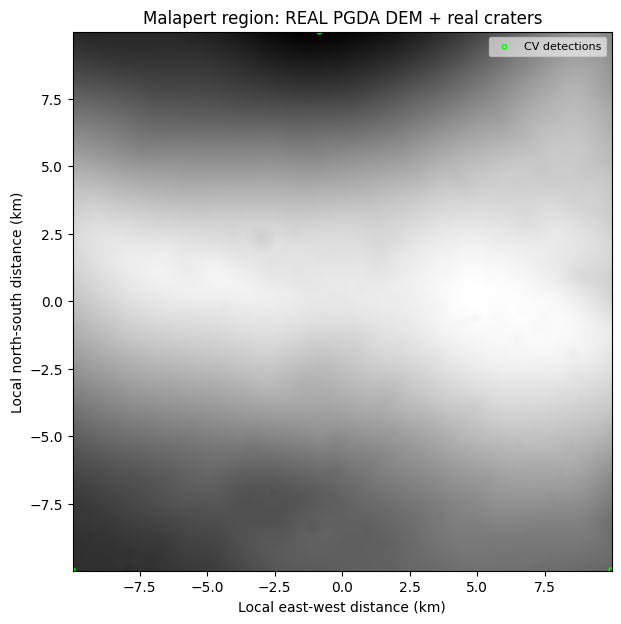

In [9]:
dets_b = craters.detect_craters(crop_b, min_radius_km=3.0, max_radius_km=40.0, threshold=0.03)
val_b = craters.validate_against_catalog(dets_b, catalog_window_b, match_radius_km=10.0)
print(f"CV detections on real terrain: {len(dets_b.lat)}")
print(f"Matched to real catalog craters: {val_b.n_matched}/{val_b.n_catalog_in_window}")

fig, ax = plt.subplots(figsize=(7, 7))
viz.plot_dem_with_craters(crop_b, dets_b, catalog_window_b, "Malapert region: REAL PGDA DEM + real craters", ax=ax)
plt.show()

### Illumination near the pole: a fundamentally different mechanism

At ~86S the sun's elevation angle is *always* within about 1.5 deg of the local horizon (the Moon's axial tilt is only 1.54 deg). So whether a point is lit is no longer mostly about slope-facing geometry -- it's about whether **nearby terrain physically blocks the sun**. This is the real mechanism behind the Moon's permanently-shadowed crater floors near the poles, and its rare "peaks of eternal light" -- elevated massifs (like Malapert) stand above the horizon-blocking terrain around them and so catch far more sunlight over a lunar day.

Ray-tracing this exactly needs full sun-position/time-of-day horizon simulation against the DEM -- out of scope even now that the real DEM itself is in hand. `illumination.polar_illumination_proxy()` instead scores height above the local median terrain -- the first-order physical driver of the real effect -- as an explicit, labeled **proxy**, not a validated illumination product. This proxy nature is a property of the illumination *model*, independent of whether the terrain under it is real or synthetic.

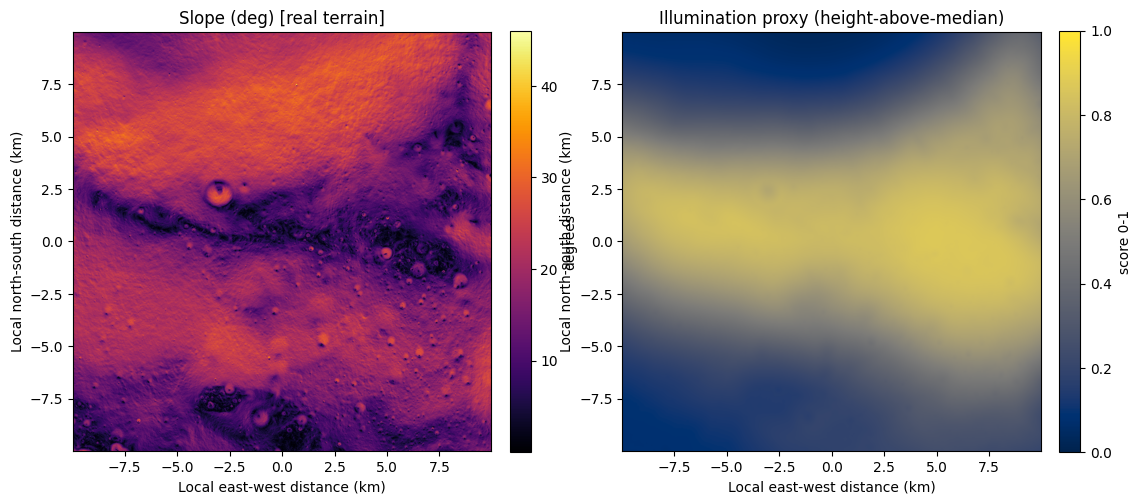

In [10]:
tm_b = terrain.compute_terrain_metrics(crop_b)
illum_b = illumination.polar_illumination_proxy(crop_b)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
viz.plot_layer(tm_b.slope_deg, crop_b, "Slope (deg) [real terrain]", "inferno", "degrees", ax=axes[0])
viz.plot_layer(illum_b, crop_b, "Illumination proxy (height-above-median)", "cividis", "score 0-1", ax=axes[1], vmin=0, vmax=1)
plt.show()

Best-scoring site: lat=-85.962, lon=2.491, score=99.9/100


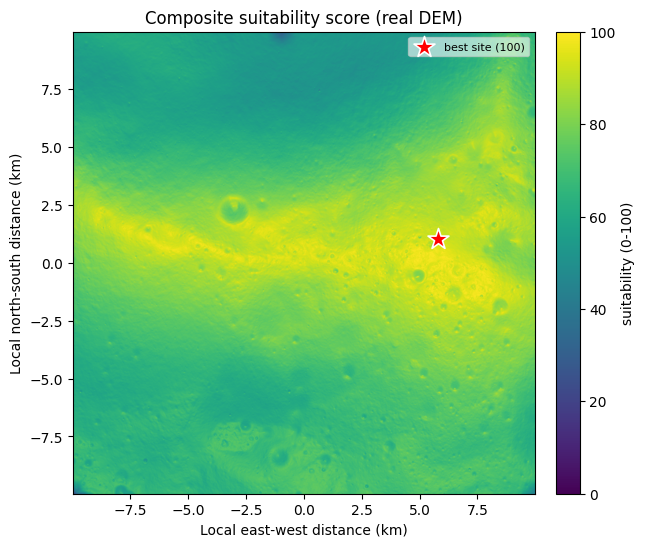

In [11]:
density_b = craters.crater_density_map(crop_b, dets_b, grid_cells=32)
suitability_b = scoring.compute_suitability(density_b, tm_b.slope_deg, illum_b)
best_b = scoring.best_site(suitability_b, crop_b)

print(f"Best-scoring site: lat={best_b['lat']:.3f}, lon={best_b['lon']:.3f}, score={best_b['score']:.1f}/100")

fig, ax = plt.subplots(figsize=(7, 6))
viz.plot_suitability(suitability_b, crop_b, best=best_b, title="Composite suitability score (real DEM)", ax=ax)
plt.show()

## Takeaways

- On real data at both sites, the classical-CV crater detector recalls the great majority of the published catalog's craters, and every hazard/benefit layer is computed directly from genuine elevation measurements.
- The Malapert Massif case study applies the identical scoring framework to a real, named, Artemis III candidate site, using NASA's own real 5 m/pixel PGDA elevation data and the same real Head et al. crater catalog used at Tycho.
- The one place the two regions still genuinely differ is the illumination model: Tycho uses the full cosine-incidence law; Malapert, where the sun sits almost exactly on the horizon, uses an explicit height-based proxy rather than full horizon ray-tracing -- clearly labeled as such wherever it's used.
- A YOLOv8 fine-tuning upgrade over the classical-CV baseline is explored separately -- see the README's "YOLOv8 stretch goal" section and `yolo_stretch/`.